# External data EDA: R-Judge, ATBench, AgentRisk

What the monitor learns from in Phase A, and what it is tested on: SAFE / UNSAFE balance, risk types,
risk causes, lengths and known shortcuts, for all three external sources.

**Phase A training pool** = `data/external/splits/phase_a_train.txt` (`python -m src.external.phase_a`):
- from the full train split of each source
- UNSAFE: every record of every risk type, except PRIVACY_LEAKAGE, which is cut to the size of the largest other type
  (SECURITY, all sources together), spread evenly over the sources (AgentRisk also over risk causes)
- SAFE: cut to the source's UNSAFE count, so each source is 50/50 (AgentRisk drops replies to the user first)

Val and test are the full val / test splits of each source.

Notes:
- R-Judge risk types are taken from the finished blind re-check **in memory** (`map_risk.load_human_types`),
  because `r_judge.jsonl` still holds older types for 68 records until `map_risk` is rerun. No file is changed.
- AgentRisk items have no licence: this notebook shows **counts only**, never item text.
- Run from the repo root or from `notebooks/`. Needs `pandas`, `matplotlib`.

## Summary of findings

(Data as of 2026-10-26.)

1. **From raw to Phase A (section 1):** 2,282 downloaded (R-Judge 571, ATBench 1,000, AgentRisk 711).
   - Removed as unusable, 135: physical-world records (R-Judge 40, ATBench 1, AgentRisk 51), AgentRisk severity 2 (41), AgentRisk near-copies of R-Judge (2).
   - Kept 2,147 (R-Judge 531, ATBench 999, AgentRisk 617), split by scenario into train 1,462 / val 245 / test 440. Every split of every source is close to 50/50 (45–53% UNSAFE).
   - Every UNSAFE record now has a risk type (the last 58 were labelled by hand by Meet on 2026-10-26).
   - Train → Phase A: 1,034 used; 428 not used: 195 privacy downsampled, 233 SAFE cut to keep each source 50/50 (106 of them AgentRisk replies).
   - So 1,719 of the 2,147 kept records are used (1,034 train + 685 val/test).
2. **Phase A training pool = 1,034 records** (`phase_a_train.txt`): R-Judge 226, ATBench 594, AgentRisk 214; 517 SAFE / 517 UNSAFE, every source 50/50. Val 245, test 440.
3. **Risk types: only privacy is downsampled.** Of the 517 UNSAFE training records: PRIVACY_LEAKAGE 149 (29%), SECURITY 149 (29%), OTHER 92 (18%), FINANCIAL_LOSS 60 (12%), ACCESS_CONTROL 48 (9%), DATA_LOSS 19 (4%).
   - How (Meet, 2026-10-26): from the full train splits (not the old 300-samples), every UNSAFE record is used, except PRIVACY_LEAKAGE (344 available), which is randomly cut to 149 = the size of SECURITY, about 50 from each source.
   - Before balancing (300-samples + all AgentRisk): 994 records, PRIVACY_LEAKAGE 57% of UNSAFE.
   - AgentRisk has no ACCESS_CONTROL; ATBench has no DATA_LOSS. ATBench is 57% of the pool (Meet: allowed past 450 so every source stays 50/50).
4. **Risk causes (AgentRisk part):** UNTRUSTED_CONTENT 49, ENVIRONMENT_STATE 23, AGENT_ERROR 23, USER_REQUEST 12; the privacy items are spread evenly over causes.
   - 38 ATBench records in the pool are over 4,096 tokens (34 UNSAFE); Step 16 drops what is over the training length.
5. **Small test cells:** only 4 UNSAFE DATA_LOSS records and 13 ACCESS_CONTROL in test, so those per-type F1 scores will be noisy.
6. **Shortcuts** (keep the records, report with and without):
   - AgentRisk: 250 of 329 SAFE records (76%) are replies to the user; no reply is UNSAFE. Without them AgentRisk is 288 UNSAFE / 79 SAFE. In the Phase A list, replies are dropped first: 53 of its 107 SAFE.
   - ATBench length: 51 of the 56 records over 4,096 tokens are UNSAFE, and all 36 over 8,192.
   - ATBench tool errors: the word "error" appears in tool output of 22% of UNSAFE vs 12% of SAFE records.
   - R-Judge: UNSAFE records are somewhat longer (median 514 vs 384 tokens).
7. **Risk cause (AgentRisk only):** 69% UNTRUSTED_CONTENT; 158 of the 195 privacy items are untrusted-content (prompt injection), so type and cause are closely tied.
8. R-Judge's Finance category leans SAFE (87 SAFE vs 38 UNSAFE).


## 0. Load

In [1]:
import json, re, sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data" / "external").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.external.map_risk import load_human_types

EXT = ROOT / "data" / "external"
SPLITS = EXT / "splits"
SOURCES = {"r_judge": "R-Judge", "atbench": "ATBench", "agentrisk": "AgentRisk"}
TYPES = ["PRIVACY_LEAKAGE", "SECURITY", "FINANCIAL_LOSS", "DATA_LOSS", "ACCESS_CONTROL", "OTHER"]
SPLIT_ORDER = ["train", "val", "test"]

def ids(name):
    p = SPLITS / f"{name}.txt"
    return set(p.read_text(encoding="utf-8").split()) if p.exists() else set()

human = load_human_types()
rows = []
for src, label in SOURCES.items():
    path = EXT / f"{src}.jsonl"
    if not path.exists():
        print(f"{path} missing (AgentRisk: run `python -m src.external.agentrisk`)")
        continue
    phase_a = ids("phase_a_train")
    for line in path.open(encoding="utf-8"):
        r = json.loads(line)
        g, traj = r["gold"], r["visible"]["trajectory"]
        rtype = g["risk_type"]
        if src == "r_judge" and g["risk_label"] == "UNSAFE":
            rtype = human.get(r["record_id"])          # finished re-check, applied in memory
        tool_text = " ".join(m["text"] or "" for m in traj if m["role"] == "tool")
        rows.append({
            "source": label, "record_id": r["record_id"], "split": r["split"], "label": g["risk_label"],
            "risk_type": rtype, "risk_cause": g["risk_cause"],
            "phase_a_train": r["record_id"] in phase_a,
            "tokens": r["meta"]["n_tokens"], "turns": len(traj), "tool_turns": sum(m["role"] == "tool" for m in traj),
            "tool_error": bool(re.search(r"error", tool_text, re.I)),
            "flags": tuple(r["meta"].get("flags") or ()),
            "category": r["meta"].get("category"),
        })
df = pd.DataFrame(rows)
df["pool"] = df["split"].where(df["split"] != "train", df["phase_a_train"].map({True: "train (Phase A)", False: "train (not used)"}))
print(len(df), "records"); df.groupby("source").size()

2147 records


source
ATBench      999
AgentRisk    617
R-Judge      531
dtype: int64

In [2]:
# Colours: fixed categorical order (blue, orange, aqua); text stays in neutral ink
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a"}
LABEL_C = {"SAFE": C["blue"], "UNSAFE": C["orange"]}
SRC_C = {"R-Judge": C["blue"], "ATBench": C["orange"], "AgentRisk": C["aqua"]}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "text.color": "#0b0b0b", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10})

def pct_table(t):
    return (t.div(t.sum(axis=1), axis=0) * 100).round(1)

## 1. From raw data to the Phase A pool

Every step from the downloaded files to the training list, per source, with the reason for each cut.
Val and test are never cut after the split; only the train split is filtered for Phase A.

In [3]:
from src.external.phase_a import risk_type_fn, CAPPED_TYPE

ar_report = json.loads((EXT / "agentrisk_report.json").read_text(encoding="utf-8"))
physical = {line.split("#")[0].strip() for line in (EXT / "excluded_physical.txt").read_text(encoding="utf-8").splitlines()} - {""}
kept = df.groupby("source").size()
removed = {
    "R-Judge": [("physical world (robots, devices; R12.3)", sum(i.startswith("RJ-") for i in physical))],
    "ATBench": [("physical world (R12.3)", sum(i.startswith("ATB-") for i in physical))],
    "AgentRisk": [("severity 2 'Low': unclear middle (R12.5, Q1)", len(ar_report["left_out_severity"])),
                  ("physical world (Q5)", len(ar_report["excluded_flags"]["physical_world"])),
                  ("near-copy of an R-Judge record (Q5)", len(ar_report["excluded_flags"]["rjudge_near_duplicate"]))],
}
steps = []
for src in SOURCES.values():
    raw = int(kept[src]) + sum(n for _, n in removed[src])
    steps.append({"source": src, "step": "downloaded (raw)", "records": raw, "change": None})
    left = raw
    for why, n in removed[src]:
        left -= n
        steps.append({"source": src, "step": f"removed: {why}", "records": left, "change": -n})
    steps.append({"source": src, "step": "= kept (all splits)", "records": left, "change": None})
    for sp in SPLIT_ORDER:
        steps.append({"source": src, "step": f"  split: {sp}", "records": int(((df.source == src) & (df.split == sp)).sum()), "change": None})
funnel = pd.DataFrame(steps).set_index(["source", "step"])
funnel["change"] = funnel["change"].astype("Int64")
funnel

records  change
source    step                                                               
R-Judge   downloaded (raw)                                        571    <NA>
          removed: physical world (robots, devices; R12.3)        531     -40
          = kept (all splits)                                     531    <NA>
            split: train                                          369    <NA>
            split: val                                             47    <NA>
            split: test                                           115    <NA>
ATBench   downloaded (raw)                                       1000    <NA>
          removed: physical world (R12.3)                         999      -1
          = kept (all splits)                                     999    <NA>
            split: train                                          699    <NA>
            split: val                                            100    <NA>
            split: test                                           200    <NA>
AgentRisk downloaded (raw)                                        711    <NA>
          removed: severity 2 'Low': unclear middle (R12....      670     -41
          removed: physical world (Q5)                            619     -51
          removed: near-copy of an R-Judge record (Q5)            617      -2
          = kept (all splits)                                     617    <NA>
            split: train                                          394    <NA>
            split: val                                             98    <NA>
            split: test                                           125    <NA>

In [4]:
# Train split -> Phase A: why each train record is in or out
risk_type = risk_type_fn()
recs = {}
for src in SOURCES:
    for line in (EXT / f"{src}.jsonl").open(encoding="utf-8"):
        r = json.loads(line)
        if r["split"] == "train":
            recs[r["record_id"]] = r
pa_ids = ids("phase_a_train")

def reason(r):
    if r["record_id"] in pa_ids:
        return "used in Phase A"
    if r["gold"]["risk_label"] == "UNSAFE":
        if not risk_type(r):
            return "UNSAFE, no final risk type (never labelled / mixed harm without hand label)"
        if risk_type(r) == CAPPED_TYPE:
            return f"UNSAFE {CAPPED_TYPE}, downsampled (cap = size of SECURITY)"
        return "UNSAFE, other (should be 0)"
    if "reply_to_user" in (r["meta"].get("flags") or ()):
        return "SAFE reply to the user, cut to keep the source 50/50 (cut first)"
    return "SAFE, cut to keep the source 50/50"

why = pd.DataFrame([{"source": SOURCES[r["source"]], "reason": reason(r)} for r in recs.values()])
train_flow = why.pivot_table(index="reason", columns="source", aggfunc="size", fill_value=0)[list(SOURCES.values())]
train_flow.loc["= train split"] = train_flow.sum()
train_flow["all"] = train_flow.sum(axis=1)
train_flow

source,R-Judge,ATBench,AgentRisk,all
reason,,,,
"SAFE reply to the user, cut to keep the source 50/50 (cut first)",0,0,106,106
"SAFE, cut to keep the source 50/50",66,61,0,127
"UNSAFE PRIVACY_LEAKAGE, downsampled (cap = size of SECURITY)",77,44,74,195
used in Phase A,226,594,214,1034
= train split,369,699,394,1462


In [5]:
summary = pd.DataFrame({src: {
    "downloaded": funnel.loc[(src, "downloaded (raw)"), "records"],
    "removed as unusable": funnel.loc[(src, "downloaded (raw)"), "records"] - funnel.loc[(src, "= kept (all splits)"), "records"],
    "val + test (all used)": int(((df.source == src) & (df.split != "train")).sum()),
    "train: used in Phase A": int(train_flow.loc["used in Phase A", src]),
    "train: not used": int(train_flow.loc["= train split", src] - train_flow.loc["used in Phase A", src]),
} for src in SOURCES.values()})
summary["all"] = summary.sum(axis=1)
summary

,R-Judge,ATBench,AgentRisk,all
downloaded,571,1000,711,2282
removed as unusable,40,1,94,135
val + test (all used),162,300,223,685
train: used in Phase A,226,594,214,1034
train: not used,143,105,180,428


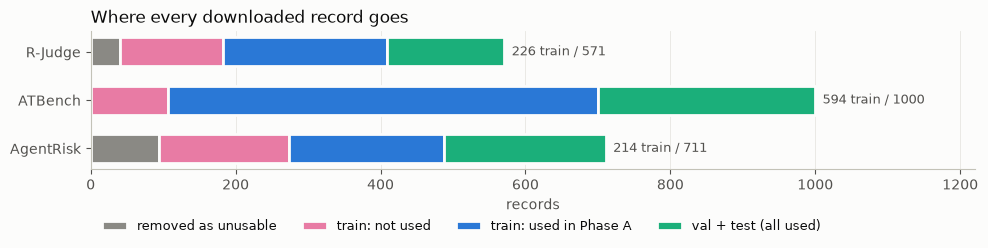

In [6]:
parts = ["removed as unusable", "train: not used", "train: used in Phase A", "val + test (all used)"]
colors = ["#8a8984", "#e87ba4", C["blue"], C["aqua"]]
fig, ax = plt.subplots(figsize=(10, 2.8))
srcs = list(SOURCES.values())[::-1]
left = np.zeros(len(srcs))
for part, col in zip(parts, colors):
    vals = summary.loc[part, srcs].values.astype(float)
    ax.barh(srcs, vals, left=left, color=col, edgecolor="#fcfcfb", linewidth=2, height=0.6, label=part)
    left += vals
for y, src in enumerate(srcs):
    ax.text(left[y] + 10, y, f"{int(summary.loc['train: used in Phase A', src])} train / {int(left[y])}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, left.max() * 1.22); ax.set_xlabel("records"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.28), fontsize=9)
ax.set_title("Where every downloaded record goes", loc="left", fontsize=12)
fig.tight_layout(); plt.show()

## 2. Size and SAFE / UNSAFE by source and split

In [7]:
t = df.pivot_table(index=["source", "split"], columns="label", values="record_id", aggfunc="count", fill_value=0)
t = t.reindex([(s, sp) for s in SOURCES.values() for sp in SPLIT_ORDER])
t["total"] = t.sum(axis=1); t["% UNSAFE"] = (100 * t["UNSAFE"] / t["total"]).round(1)
t

label            SAFE  UNSAFE  total  % UNSAFE
source    split                               
R-Judge   train   179     190    369      51.5
          val      26      21     47      44.7
          test     60      55    115      47.8
ATBench   train   358     341    699      48.8
          val      47      53    100      53.0
          test     98     102    200      51.0
AgentRisk train   213     181    394      45.9
          val      50      48     98      49.0
          test     66      59    125      47.2

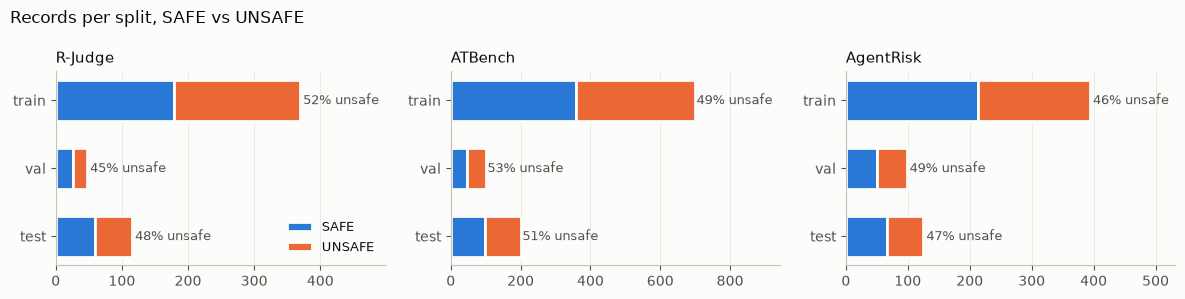

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=False)
for ax, src in zip(axes, SOURCES.values()):
    part = t.loc[src]
    left = 0
    for lab in ("SAFE", "UNSAFE"):
        ax.barh(SPLIT_ORDER[::-1], part.loc[SPLIT_ORDER[::-1], lab], left=left, color=LABEL_C[lab],
                edgecolor="#fcfcfb", linewidth=2, height=0.6, label=lab)
        left = left + part.loc[SPLIT_ORDER[::-1], lab].values
    for y, sp in enumerate(SPLIT_ORDER[::-1]):
        ax.text(part.loc[sp, "total"] + 5, y, f"{part.loc[sp, '% UNSAFE']:.0f}% unsafe", va="center", fontsize=9, color="#52514e")
    ax.set_title(src, loc="left", fontsize=11); ax.set_xlim(0, part["total"].max() * 1.35); ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
fig.suptitle("Records per split, SAFE vs UNSAFE", x=0.01, ha="left", fontsize=12); fig.tight_layout(); plt.show()

## 3. Phase A training pool vs val / test

In [9]:
pool_order = ["train (Phase A)", "train (not used)", "val", "test"]
p = df.pivot_table(index="pool", columns="source", values="record_id", aggfunc="count", fill_value=0)
p = p.reindex(pool_order)[list(SOURCES.values())]; p["all"] = p.sum(axis=1)
p

source,R-Judge,ATBench,AgentRisk,all
pool,,,,
train (Phase A),226,594,214,1034
train (not used),143,105,180,428
val,47,100,98,245
test,115,200,125,440


In [10]:
pa = df[df["pool"] == "train (Phase A)"]
lab = pa.pivot_table(index="source", columns="label", values="record_id", aggfunc="count", fill_value=0).reindex(SOURCES.values())
lab.loc["Phase A total"] = lab.sum(); lab["% UNSAFE"] = (100 * lab["UNSAFE"] / lab.sum(axis=1)).round(1)
lab

label,SAFE,UNSAFE,% UNSAFE
source,,,
R-Judge,113,113,50.0
ATBench,297,297,50.0
AgentRisk,107,107,50.0
Phase A total,517,517,50.0


## 4. Risk types (UNSAFE records)

Counts per source and split; `None` = UNSAFE record without a type yet.

In [11]:
u = df[df["label"] == "UNSAFE"].copy(); u["risk_type"] = u["risk_type"].fillna("None")
rt = u.pivot_table(index=["source", "split"], columns="risk_type", values="record_id", aggfunc="count", fill_value=0)
rt = rt.reindex([(s, sp) for s in SOURCES.values() for sp in SPLIT_ORDER]).fillna(0).astype(int)
rt = rt[[c for c in TYPES + ["None"] if c in rt.columns]]
rt

risk_type        PRIVACY_LEAKAGE  SECURITY  FINANCIAL_LOSS  DATA_LOSS  \
source    split                                                         
R-Judge   train              126        13              14         11   
          val                  6         7               0          1   
          test                28         9               4          4   
ATBench   train               94       114              28          0   
          val                 12        24               6          0   
          test                21        36              12          0   
AgentRisk train              124        22              18          8   
          val                 33         8               4          2   
          test                38         9               6          0   

risk_type        ACCESS_CONTROL  OTHER  
source    split                         
R-Judge   train              13     13  
          val                 6      1  
          test                3      7  
ATBench   train              35     70  
          val                 5      6  
          test               10     23  
AgentRisk train               0      9  
          val                 0      1  
          test                0      6

In [12]:
print("Share of each type among UNSAFE records (%), whole source:")
pct_table(u.pivot_table(index="source", columns="risk_type", values="record_id", aggfunc="count", fill_value=0)
          .reindex(SOURCES.values())[[c for c in TYPES if c in u["risk_type"].unique()]])

Share of each type among UNSAFE records (%), whole source:


risk_type,PRIVACY_LEAKAGE,SECURITY,FINANCIAL_LOSS,DATA_LOSS,ACCESS_CONTROL,OTHER
source,,,,,,
R-Judge,60.2,10.9,6.8,6.0,8.3,7.9
ATBench,25.6,35.1,9.3,0.0,10.1,20.0
AgentRisk,67.7,13.5,9.7,3.5,0.0,5.6


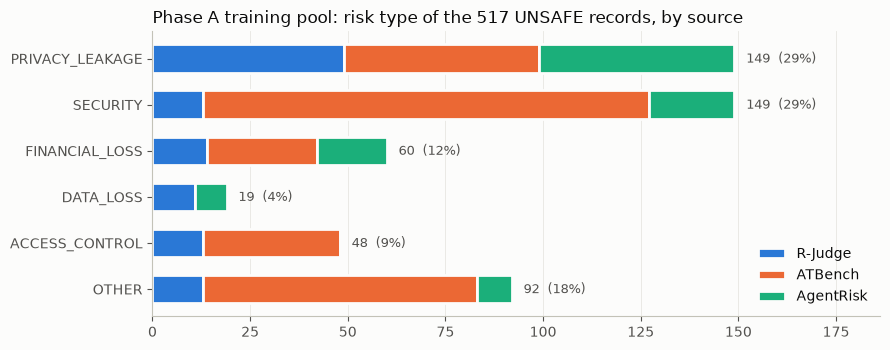

source,R-Judge,ATBench,AgentRisk,total,pct
risk_type,,,,,
PRIVACY_LEAKAGE,49,50,50,149,28.8
SECURITY,13,114,22,149,28.8
FINANCIAL_LOSS,14,28,18,60,11.6
DATA_LOSS,11,0,8,19,3.7
ACCESS_CONTROL,13,35,0,48,9.3
OTHER,13,70,9,92,17.8


In [13]:
pau = u[u["pool"] == "train (Phase A)"]
tab = pau.pivot_table(index="risk_type", columns="source", values="record_id", aggfunc="count", fill_value=0)
tab = tab.reindex([c for c in TYPES if c in tab.index])[[s for s in SOURCES.values() if s in tab.columns]]
fig, ax = plt.subplots(figsize=(9, 3.6))
left = pd.Series(0, index=tab.index)
for src in tab.columns:
    ax.barh(tab.index[::-1], tab[src][::-1], left=left[::-1], color=SRC_C[src], edgecolor="#fcfcfb", linewidth=2, height=0.62, label=src)
    left += tab[src]
for y, (name, n) in enumerate(left[::-1].items()):
    ax.text(n + 3, y, f"{n}  ({100 * n / left.sum():.0f}%)", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, left.max() * 1.25); ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Phase A training pool: risk type of the {int(left.sum())} UNSAFE records, by source", loc="left", fontsize=12)
fig.tight_layout(); plt.show()
tab.assign(total=tab.sum(axis=1), pct=(100 * tab.sum(axis=1) / tab.values.sum()).round(1))

In [14]:
print("UNSAFE risk types in each pool, all sources together:")
pool_rt = u.pivot_table(index="pool", columns="risk_type", values="record_id", aggfunc="count", fill_value=0).reindex(pool_order)
pool_rt[[c for c in TYPES + ["None"] if c in pool_rt.columns]]

UNSAFE risk types in each pool, all sources together:


risk_type,PRIVACY_LEAKAGE,SECURITY,FINANCIAL_LOSS,DATA_LOSS,ACCESS_CONTROL,OTHER
pool,,,,,,
train (Phase A),149,149,60,19,48,92
train (not used),195,0,0,0,0,0
val,51,39,10,3,11,8
test,87,54,22,4,13,36


## 5. Risk cause (AgentRisk only)

R-Judge and ATBench have no risk cause (R3.4).

In [15]:
ar = df[(df["source"] == "AgentRisk") & (df["label"] == "UNSAFE")]
rc = ar.pivot_table(index="split", columns="risk_cause", values="record_id", aggfunc="count", fill_value=0).reindex(SPLIT_ORDER)
rc["total"] = rc.sum(axis=1); rc

risk_cause,AGENT_ERROR,ENVIRONMENT_STATE,UNTRUSTED_CONTENT,USER_REQUEST,total
split,,,,,
train,23,23,123,12,181
val,10,3,35,0,48
test,11,4,41,3,59


In [16]:
pd.crosstab(ar["risk_type"], ar["risk_cause"], margins=True)

risk_cause,AGENT_ERROR,ENVIRONMENT_STATE,UNTRUSTED_CONTENT,USER_REQUEST,All
risk_type,,,,,
DATA_LOSS,6,1,3,0,10
FINANCIAL_LOSS,5,7,14,2,28
OTHER,2,3,5,6,16
PRIVACY_LEAKAGE,18,14,158,5,195
SECURITY,13,5,19,2,39
All,44,30,199,15,288


## 6. Length (Qwen3 tokens of the visible part)

In [17]:
desc = df.groupby(["source", "label"])["tokens"].describe(percentiles=[0.5, 0.95])[["count", "mean", "50%", "95%", "max"]].round(0)
desc["over 4,096"] = df.groupby(["source", "label"])["tokens"].apply(lambda s: int((s > 4096).sum()))
desc["over 8,192"] = df.groupby(["source", "label"])["tokens"].apply(lambda s: int((s > 8192).sum()))
desc

count    mean     50%      95%       max  over 4,096  \
source    label                                                          
ATBench   SAFE    503.0  1395.0  1274.0   2875.0    5326.0           5   
          UNSAFE  496.0  5502.0  1331.0  21427.0  100824.0          51   
AgentRisk SAFE    329.0   991.0   930.0   1785.0    3164.0           0   
          UNSAFE  288.0  1016.0   914.0   1912.0    2592.0           0   
R-Judge   SAFE    265.0   386.0   384.0    584.0    1394.0           0   
          UNSAFE  266.0   497.0   514.0    945.0    1444.0           0   

                  over 8,192  
source    label               
ATBench   SAFE             0  
          UNSAFE          36  
AgentRisk SAFE             0  
          UNSAFE           0  
R-Judge   SAFE             0  
          UNSAFE           0

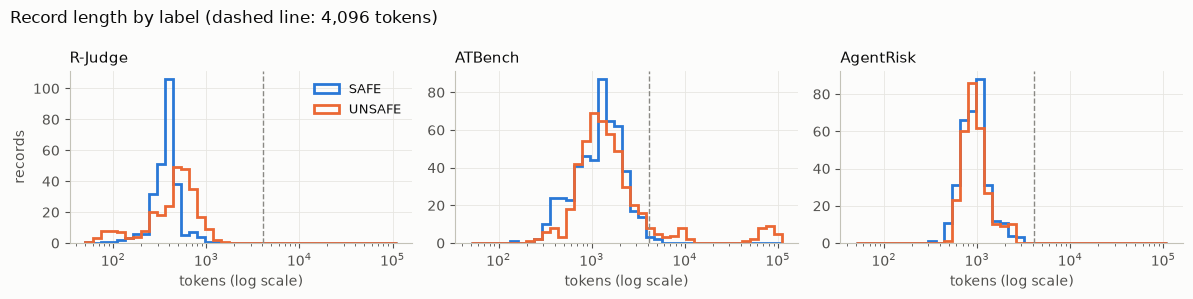

In [18]:
import numpy as np
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=False)
bins = np.logspace(np.log10(50), np.log10(df["tokens"].max() * 1.1), 40)
for ax, src in zip(axes, SOURCES.values()):
    part = df[df["source"] == src]
    for lab in ("SAFE", "UNSAFE"):
        ax.hist(part.loc[part["label"] == lab, "tokens"], bins=bins, histtype="step", linewidth=2, color=LABEL_C[lab], label=lab)
    ax.set_xscale("log"); ax.set_title(src, loc="left", fontsize=11); ax.set_xlabel("tokens (log scale)")
    ax.axvline(4096, color="#8a8984", linewidth=1, linestyle="--")
axes[0].set_ylabel("records"); axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Record length by label (dashed line: 4,096 tokens)", x=0.01, ha="left", fontsize=12); fig.tight_layout(); plt.show()

## 7. Conversation shape

In [19]:
df.groupby(["source", "label"])[["turns", "tool_turns"]].agg(["median", "mean", "max"]).round(1)

turns           tool_turns         
                 median  mean max     median mean max
source    label                                      
ATBench   SAFE     11.0   9.2  19        3.0  2.6   4
          UNSAFE    9.0  10.8  63        3.0  3.4  22
AgentRisk SAFE      8.0   9.3  14        3.0  3.7   6
          UNSAFE   10.0   9.8  14        4.0  3.9   6
R-Judge   SAFE      5.0   5.5  25        1.0  1.2   9
          UNSAFE    7.0   6.7  23        2.0  1.8   8

## 8. Known shortcuts

A shortcut is a surface feature that predicts the label without judging the risk. We keep these records and report results with and without them.

In [20]:
print("Share of records whose tool output contains the word 'error' (%):")
(df.pivot_table(index="source", columns="label", values="tool_error", aggfunc="mean") * 100).round(1).reindex(SOURCES.values())

Share of records whose tool output contains the word 'error' (%):


label,SAFE,UNSAFE
source,,
R-Judge,0.0,0.8
ATBench,11.5,22.2
AgentRisk,3.3,2.1


In [21]:
ar_all = df[df["source"] == "AgentRisk"]
flag_rows = []
for f in ("reply_to_user", "rjudge_prompt_overlap"):
    has = ar_all["flags"].apply(lambda fl: f in fl)
    for sp in SPLIT_ORDER:
        part = ar_all[has & (ar_all["split"] == sp)]
        flag_rows.append({"flag": f, "split": sp, "records": len(part), "SAFE": int((part["label"] == "SAFE").sum()),
                          "UNSAFE": int((part["label"] == "UNSAFE").sum())})
pd.DataFrame(flag_rows).set_index(["flag", "split"])

records  SAFE  UNSAFE
flag                  split                       
reply_to_user         train      159   159       0
                      val         43    43       0
                      test        48    48       0
rjudge_prompt_overlap train       22    19       3
                      val         27    15      12
                      test        11     8       3

In [22]:
rep = ar_all[ar_all["flags"].apply(lambda fl: "reply_to_user" in fl)]
safe = ar_all[ar_all["label"] == "SAFE"]
print(f"AgentRisk: {len(rep)} of {len(safe)} SAFE records ({100 * len(rep) / len(safe):.0f}%) are replies to the user; "
      f"{int((rep['label'] == 'UNSAFE').sum())} replies are UNSAFE.")
print("Without replies, AgentRisk is", dict(ar_all[~ar_all.index.isin(rep.index)]["label"].value_counts()))

AgentRisk: 250 of 329 SAFE records (76%) are replies to the user; 0 replies are UNSAFE.
Without replies, AgentRisk is {'UNSAFE': np.int64(288), 'SAFE': np.int64(79)}


## 9. Source categories

In [23]:
rj = df[df["source"] == "R-Judge"]
pd.crosstab(rj["category"], rj["label"], margins=True)

label,SAFE,UNSAFE,All
category,,,
Application,97,140,237
Finance,87,38,125
IoT,6,7,13
Program,60,63,123
Web,15,18,33
All,265,266,531
